# 02 · Check the results

This notebook checks the README's claims from the saved arrays in `results/`, in about a minute and
without the raw videos. Each section takes one claim:

1. What the model was fitted on, and what was held out.
2. The held-out errors follow from the saved predictions and measurements.
3. The prediction is computed, not replayed: H1 is predicted again from its cap depth alone.
4. What the held-out predictions look like.
5. Where the error sits.
6. Damping shows in the dent under the cap, not in the whole-press score.
7. How uncertain the stiffness is.
8. The MuJoCo baseline and its follow-up checks.
9. What the soft top layer does.

After running `01_reproduce.ipynb` you can point it at your own run instead (`SOURCE = "out"`).

In [1]:
from pathlib import Path
import json, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from press2sim import fit as F, model as M, model_report as MR
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # all-NaN frames where a dot was briefly hidden

SOURCE = "results"          # "results": the reference run; "out": your own run from 01_reproduce.ipynb
if SOURCE == "results":
    MODEL, TRACKS, PREDS = ROOT / "results/model", ROOT / "results/tracks", ROOT / "results/predictions"
else:
    MODEL, TRACKS, PREDS = ROOT / "out/model", ROOT / "out/tracks", ROOT / "out/model"

fit = json.loads((MODEL / "params.json").read_text())
p = M.Params(**{k: (tuple(v) if isinstance(v, list) else v) for k, v in fit["params"].items()})
reported = pd.read_csv(MODEL / "predictions.csv").set_index("clip")
KIND = {"H1": "press", "O1": "press", "F1": "fingertip"}
clips = {c: M.load_clip(TRACKS, c, k) for c, k in KIND.items()}
preds = {c: np.load(PREDS / f"pred_{c}.npz") for c in KIND}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def scored(code):
    """Frames and dots the pipeline scores: every frame from 0.1 s before contact to the end, every dot.
    F1 is driven by the one dot under the fingertip, so that dot is left out, and it is scored from 0.5 s
    before the fingertip went 1 mm in (hands pass in front of the face earlier on)."""
    cd, P = clips[code], preds[code]
    dots = np.ones(105, bool)
    if "driving_dot" in P.files:
        dots[int(P["driving_dot"])] = False
        return (cd.t >= float(P["score_from"])) & (cd.t <= cd.t_end), dots
    return (cd.t >= cd.events["t_contact"] - 0.1) & (cd.t <= cd.t_end), dots

## 1 · What the model was fitted on

Training presses set the shape and damping, the dead weights set the stiffness, and H1, O1 and F1 were
never used. H1 is a fresh press, O1 is off-centre (under the 5th dot column), F1 is a fingertip.

In [2]:
print("training presses:", ", ".join(fit["train"]))
print("dead weights:    ", ", ".join(fit["weights"]))
print("held out:        ", ", ".join(fit["held_out"]))
assert not set(fit["held_out"]) & set(fit["train"] + fit["weights"])
pp = fit["params"]
pd.DataFrame([
    ["Young's modulus E", f"{pp['E'] / 1e3:.0f} kPa", "dead weights K1-K4"],
    ["cells buckle at strain", f"{pp['eps_y']:.3f}", "presses"],
    ["plateau slope", f"{pp['h']:.3f} x E", "presses"],
    ["crushed cells touch at strain", f"{pp['eps_d']:.2f}", "presses"],
    ["Poisson's ratio", f"{pp['nu']:.2f}", "presses"],
    ["soft top layer", f"{pp['skin_t']:.1f} mm at {pp['skin_k']:.3f} x E", "presses"],
    ["support under the block", f"{pp['support']:.4f} x E per mm", "dead weights"],
    ["relaxing fraction and time", f"{pp['g'][0]:.2f}, {pp['tau'][0]:.2f} s", "the dent after release"],
    ["dashpot", f"{pp['tau_v'] * 1e3:.2f} ms", "not fitted"],
], columns=["parameter", "value", "fitted on"])

training presses: T01, T02, T03, T04, T05, T06, T07, T08, T09, R1, R2
dead weights:     K1, K2, K3, K4
held out:         H1, O1, F1


,parameter,value,fitted on
0,Young's modulus E,185 kPa,dead weights K1-K4
1,cells buckle at strain,0.070,presses
2,plateau slope,0.070 x E,presses
3,crushed cells touch at strain,0.55,presses
4,Poisson's ratio,0.00,presses
5,soft top layer,3.0 mm at 0.055 x E,presses
6,support under the block,0.0296 x E per mm,dead weights
7,relaxing fraction and time,"0.16, 0.56 s",the dent after release
8,dashpot,1.24 ms,not fitted


## 2 · The held-out errors follow from the saved arrays

The error is the RMS over all 105 dots and every frame from 0.1 s before contact to the end of the
clip, in the face's plane. The movement is the RMS of the measured movement over the same frames. The
fingertip clip is scored a little differently; see `scored()` above.

In [3]:
rows = []
for c, cd in clips.items():
    U = preds[c]["U"]
    w, dots = scored(c)
    err = U[w][:, dots] - cd.disp[w][:, dots]
    rms_err = np.sqrt(np.nanmean(err ** 2))            # plain numpy, no press2sim code involved
    rms_mov = np.sqrt(np.nanmean(cd.disp[w] ** 2))     # the movement counts every dot
    rows.append([c, w.sum(), rms_err, rms_mov, rms_err / rms_mov,
                 reported.loc[c, "rms_error_mm"], reported.loc[c, "rms_movement_mm"]])
tab = pd.DataFrame(rows, columns=["clip", "frames", "RMS error (mm)", "RMS movement (mm)", "error / movement",
                                  "reported error (mm)", "reported movement (mm)"]).set_index("clip")
assert np.allclose(tab["RMS error (mm)"], tab["reported error (mm)"], atol=1e-3)
assert np.allclose(tab["RMS movement (mm)"], tab["reported movement (mm)"], atol=1e-3)
tab.style.format({"RMS error (mm)": "{:.2f}", "RMS movement (mm)": "{:.2f}", "error / movement": "{:.0%}",
                  "reported error (mm)": "{:.2f}", "reported movement (mm)": "{:.2f}"})

,frames,RMS error (mm),RMS movement (mm),error / movement,reported error (mm),reported movement (mm)
clip,,,,,,
H1,1100,1.17,6.93,17%,1.17,6.93
O1,1080,1.01,5.21,19%,1.01,5.21
F1,885,0.31,0.92,34%,0.31,0.92


In [4]:
print("All presses, as reported (training presses included):")
r = reported[["set", "max_depth_mm", "rms_error_mm", "rms_movement_mm", "relative_error", "error_at_deepest_mm"]]
r.style.format({"max_depth_mm": "{:.1f}", "rms_error_mm": "{:.2f}", "rms_movement_mm": "{:.2f}",
                "relative_error": "{:.0%}", "error_at_deepest_mm": "{:.2f}"})

All presses, as reported (training presses included):


,set,max_depth_mm,rms_error_mm,rms_movement_mm,relative_error,error_at_deepest_mm
clip,,,,,,
T01,training,23.9,0.57,1.86,30%,1.20
T02,training,25.6,0.82,2.58,32%,1.34
T03,training,20.4,0.96,2.10,46%,1.55
T04,training,32.6,0.81,4.09,20%,1.29
T05,training,31.9,0.88,4.44,20%,1.23
T06,training,34.0,0.88,5.06,17%,1.34
T07,training,45.1,1.48,8.34,18%,2.31
T08,training,45.5,1.62,9.18,18%,2.28
T09,training,47.6,1.65,8.98,18%,2.65


## 3 · Not a replay: predict H1 again from its cap depth alone

This rebuilds the 3D block from the fitted parameters (eleven depths, about a minute) and predicts all
105 dots of H1 from one input: the cap's depth over time, measured from the two dots on the bottle. The
dots' rest positions only say where the dots are.

In [5]:
cd = clips["H1"]
t0 = time.time()
table = M.build_table(p, ("cap", 117.0))                  # no cache: solved from scratch here
U_new, q, force, contact = M.predict_clip(cd, table, p)
print(f"block solved and H1 predicted in {time.time() - t0:.0f} s")
w, _ = scored("H1")
print(f"largest difference from the saved prediction: {np.nanmax(np.abs(U_new[w] - preds['H1']['U'][w])):.4f} mm")
print(f"RMS error against the tracked dots: {np.sqrt(np.nanmean((U_new[w] - cd.disp[w]) ** 2)):.2f} mm")

block solved and H1 predicted in 27 s
largest difference from the saved prediction: 0.0000 mm
RMS error against the tracked dots: 1.17 mm


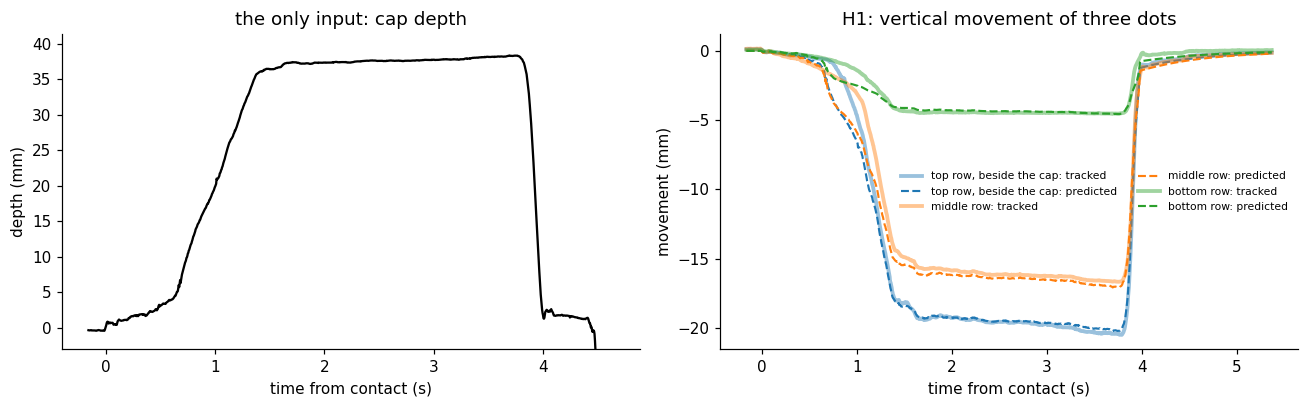

In [6]:
t = cd.t - cd.events["t_contact"]
sel = (t > -0.5) & (cd.t <= cd.t_end)                                       # press, hold, lift and recovery
top = 6 * 15 + int(np.argmin(np.abs(cd.rest[90:105, 0] - (cd.x_c + 36))))   # top row, beside the cap
mid = 3 * 15 + int(np.argmin(np.abs(cd.rest[45:60, 0] - cd.x_c)))           # middle row, under the cap
bot = int(np.argmin(np.abs(cd.rest[0:15, 0] - cd.x_c)))                      # bottom row, under the cap
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(t[sel], cd.depth[sel], "k")
ax[0].set(title="the only input: cap depth", xlabel="time from contact (s)", ylabel="depth (mm)",
          ylim=(-3, np.nanmax(cd.depth[sel]) + 3))                              # below 0: the bottle lifted off
for j, col, name in [(top, "C0", "top row, beside the cap"), (mid, "C1", "middle row"), (bot, "C2", "bottom row")]:
    ax[1].plot(t[sel], cd.disp[sel, j, 1], col, lw=2.5, alpha=0.45, label=f"{name}: tracked")
    ax[1].plot(t[sel], U_new[sel, j, 1], col + "--", lw=1.4, label=f"{name}: predicted")
ax[1].set(title="H1: vertical movement of three dots", xlabel="time from contact (s)", ylabel="movement (mm)")
ax[1].legend(fontsize=7, ncol=2, frameon=False)
plt.tight_layout(); plt.show()

## 4 · What the held-out predictions look like

Dots at the deepest moment of each held-out press: where they started (grey), where the camera saw them
(green) and where the model put them (magenta), in millimetres on the face.

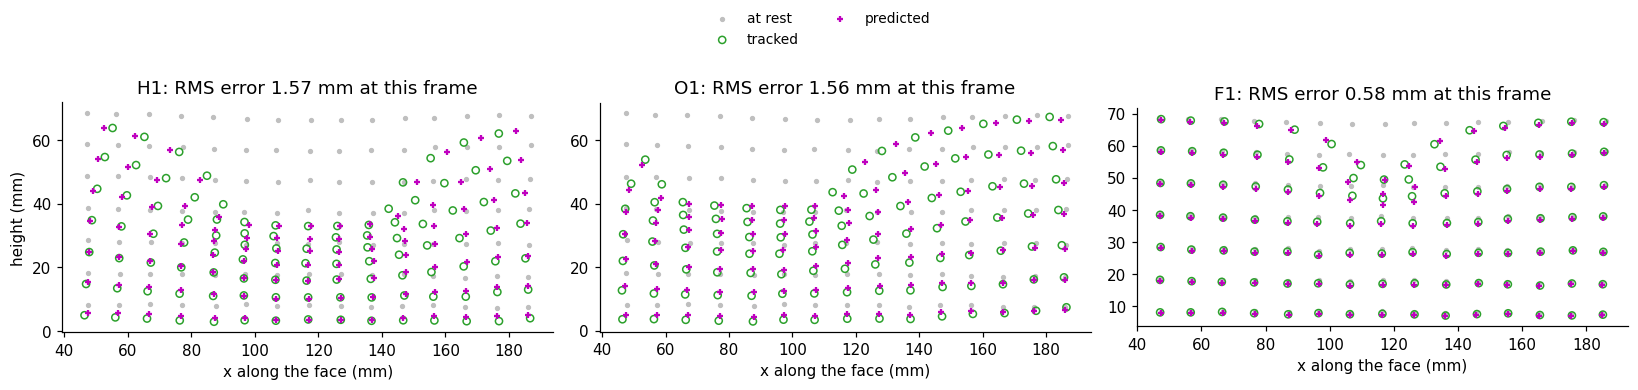

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (c, cdc) in zip(axs, clips.items()):
    U = preds[c]["U"]
    w, dots = scored(c)
    if "t_max" in cdc.events:
        k = int(np.searchsorted(cdc.t, cdc.events["t_max"]))
    else:                                                      # fingertip: deepest point of its indentation
        k = int(np.nanargmax(np.where(w, preds[c]["q"], -np.inf)))
    R = cdc.rest
    ax.scatter(R[:, 0], R[:, 1], s=6, c="0.75", label="at rest")
    ax.scatter(R[:, 0] + cdc.disp[k, :, 0], R[:, 1] + cdc.disp[k, :, 1], s=22, facecolors="none",
               edgecolors="tab:green", label="tracked")
    ax.scatter(R[:, 0] + U[k, :, 0], R[:, 1] + U[k, :, 1], s=12, marker="+", c="m", label="predicted")
    e = np.sqrt(np.nanmean((U[k][dots] - cdc.disp[k][dots]) ** 2))
    ax.set(title=f"{c}: RMS error {e:.2f} mm at this frame", xlabel="x along the face (mm)", aspect="equal")
axs[0].set_ylabel("height (mm)")
fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()

## 5 · Where the error sits

By row, the error is largest in the top row (beside the cap) and smallest in the bottom row. Over time
it peaks at the deepest frames, when the foam is most crushed.

,top row (mm),middle row (mm),bottom row (mm)
clip,,,
H1,1.72,0.83,0.62
O1,1.64,0.79,0.59
F1,0.39,0.26,0.12


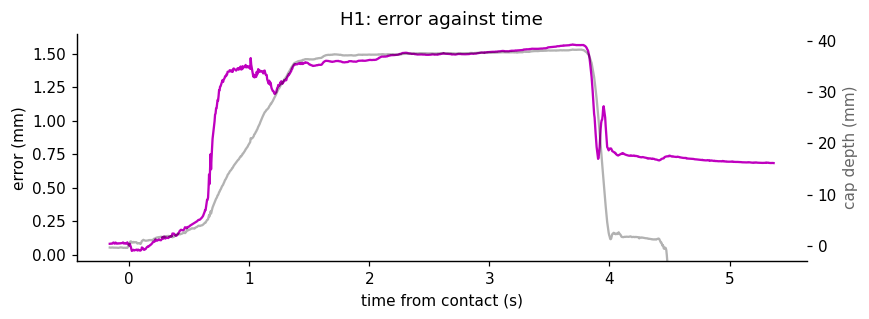

In [8]:
rows = []
for c, cdc in clips.items():
    w, dots = scored(c)
    err = np.where(dots[None, :, None], preds[c]["U"][w] - cdc.disp[w], np.nan)
    rows.append([c] + [np.sqrt(np.nanmean(err[:, r * 15:(r + 1) * 15] ** 2)) for r in (6, 3, 0)])
display(pd.DataFrame(rows, columns=["clip", "top row (mm)", "middle row (mm)", "bottom row (mm)"])
        .set_index("clip").round(2))

U = preds["H1"]["U"]
e_t = np.sqrt(np.nanmean((U - cd.disp) ** 2, axis=(1, 2)))
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t[sel], e_t[sel], "m", label="RMS error over all dots")
ax2 = ax.twinx(); ax2.plot(t[sel], cd.depth[sel], "k", alpha=0.3)
ax2.set_ylabel("cap depth (mm)", color="0.4"); ax2.set_ylim(-3, np.nanmax(cd.depth[sel]) + 3)
ax.set(xlabel="time from contact (s)", ylabel="error (mm)", title="H1: error against time")
plt.tight_layout(); plt.show()

## 6 · Damping shows in the dent under the cap

The model was also run with all damping switched off (`U_no_damping`). Over a whole press the two
predictions score the same to about 0.01 mm: while the cap presses, its depth sets the dots and damping
changes nothing. Damping acts once the foam lets go of the cap, in how fast the dent under it closes. So
it is fitted to, and scored on, the vertical movement of the top-row dots under the cap from the
measured release to the end of the clip. There the damped model is far closer than the undamped one.

In [9]:
rms = lambda a: np.sqrt(np.nanmean(a ** 2))
rows = []
for c, cdc in clips.items():
    P = preds[c]
    w, dots = scored(c)
    d = cdc.disp[w][:, dots]
    released = "t_release" in cdc.events                      # the fingertip clip has no such event
    rows.append([c, rms(P["U"][w][:, dots] - d), rms(P["U_no_damping"][w][:, dots] - d),
                 rms(F.dent_error(cdc, P["U"])) if released else np.nan,
                 rms(F.dent_error(cdc, P["U_no_damping"])) if released else np.nan])
pd.DataFrame(rows, columns=["clip", "whole press, damped (mm)", "whole press, undamped (mm)",
                            "dent after release, damped (mm)", "dent after release, undamped (mm)"]).set_index("clip").round(3)

,"whole press, damped (mm)","whole press, undamped (mm)","dent after release, damped (mm)","dent after release, undamped (mm)"
clip,,,,
H1,1.174,1.169,0.171,0.766
O1,1.009,1.010,0.223,0.671
F1,0.315,0.315,NaN,NaN


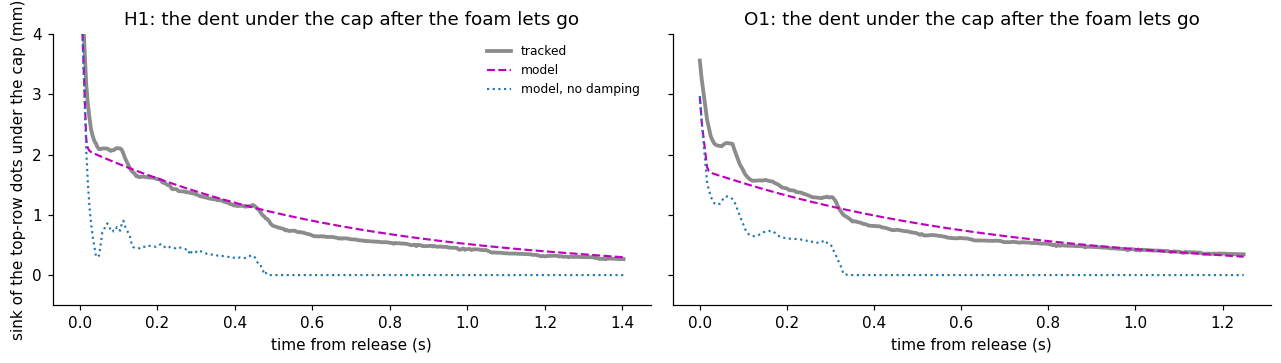

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, c in zip(axs, ("H1", "O1")):
    cdc, P = clips[c], preds[c]
    w, j = F.dent_frames(cdc), F.dent_dots(cdc)
    ts = cdc.t[w] - cdc.events["t_release"]
    ax.plot(ts, -np.nanmean(cdc.disp[w][:, j, 1], axis=1), "k", lw=2.5, alpha=0.45, label="tracked")
    ax.plot(ts, -np.nanmean(P["U"][w][:, j, 1], axis=1), "m--", lw=1.4, label="model")
    ax.plot(ts, -np.nanmean(P["U_no_damping"][w][:, j, 1], axis=1), "C0:", lw=1.4, label="model, no damping")
    ax.set(title=f"{c}: the dent under the cap after the foam lets go", xlabel="time from release (s)", ylim=(-0.5, 4))
axs[0].set_ylabel("sink of the top-row dots under the cap (mm)")
axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

The fit and its limits, from `results/model/model_checks.json` (made by `scripts/model_checks.py`): the dent
error on the training and held-out presses, the dashpot (not fitted, because neither the dent nor the
moment of release can pin it down), and a second relaxing term, which helps a little but whose time
constant these clips cannot set.

In [11]:
mchk = json.loads((MODEL / "model_checks.json").read_text())
dm = mchk["damping"]
display(pd.DataFrame(dm["dent_rms_mm"]).T.round(3))
print("dent error (training, mm) by dashpot (ms):", {k: round(v, 4) for k, v in dm["dent_rms_training_by_dashpot_ms"].items()})
print("model release minus measured (median, ms) by dashpot (ms):",
      {k: round(v["median_ms"]) for k, v in dm["release_model_minus_measured_ms_by_dashpot_ms"].items()})
two = dm["second_term"]
print(f"two relaxing terms, all free: fractions {np.round(two['free']['g'], 3).tolist()}, times {np.round(two['free']['tau_s'], 2).tolist()} s, "
      f"training {two['free']['dent_rms_training_mm']:.3f} mm, held out {two['free']['dent_rms_held_out_mm']:.3f} mm")
print("the slow term's time held at (s) -> training dent error (mm):",
      {k: round(v["dent_rms_training_mm"], 4) for k, v in two["slow_time_held_at_s"].items()})

,no damping,fitted
training,0.710,0.460
held out,0.723,0.197


dent error (training, mm) by dashpot (ms): {'0': 0.4601, '1.24': 0.4598, '5': 0.4587, '10': 0.4577, '20': 0.4592, '30': 0.4665, '50': 0.4962, '100': 0.718}
model release minus measured (median, ms) by dashpot (ms): {'0': 21, '1.24': 21, '5': 21, '10': 21, '20': 21, '30': 17, '50': 13, '100': -13}
two relaxing terms, all free: fractions [0.178, 0.052], times [0.28, 4.46] s, training 0.432 mm, held out 0.162 mm
the slow term's time held at (s) -> training dent error (mm): {'2': 0.435, '3': 0.4327, '5': 0.4322, '10': 0.4328}


## 7 · How uncertain the stiffness is

E comes from the dead weights, the only clips with a known force. Fitted to each weight alone it rises
with the load. More important, E leans on two parts of the model that the dots do not pin down: the soft
top layer and the compliant support. The second table refits E to the same four weights under other
assumptions. The dot movement in a press does not depend on E; only the predicted forces do, so treat
those as good to a factor of 2 to 3.

In [12]:
w = json.loads((MODEL / "stiffness_per_weight.json").read_text())
display(pd.DataFrame([[k, v["load_kg"], v["E_kPa"], v["sink_measured_mm"], v["sink_model_mm"]] for k, v in w.items()],
                     columns=["clip", "load (kg)", "E alone (kPa)", "sink measured (mm)", "sink with E alone (mm)"])
        .set_index("clip").round(3))
print(f"joint fit: E = {fit['stiffness']['E_Pa'] / 1e3:.0f} kPa")
alt = mchk["stiffness"]["all_four_weights"]
pd.DataFrame([[k, v["E_kPa"], v["weights_rms_mm"], v["cap_force_N"]["30 mm"]] for k, v in alt.items()],
             columns=["assumption", "E (kPa)", "weights fitted to (mm)", "force to push the cap 30 mm in (N)"]).set_index("assumption").round(2)

,load (kg),E alone (kPa),sink measured (mm),sink with E alone (mm)
clip,,,,
K1,1.000,101.119,0.627,0.648
K2,1.500,145.172,0.705,0.713
K3,2.000,170.433,0.973,0.919
K4,2.423,190.174,1.097,1.142


joint fit: E = 185 kPa


,E (kPa),weights fitted to (mm),force to push the cap 30 mm in (N)
assumption,,,
as fitted,184.78,0.23,159.69
no soft top,118.07,0.10,85.85
rigid table,147.58,0.36,132.93
"no soft top, rigid table",70.57,0.11,52.85


## 8 · The MuJoCo baseline

The same block in MuJoCo 4.0, given the same cap depth and scored on the same dots. Then the follow-up
checks: a finer grid, MuJoCo's plasticity and its Stable Neo-Hookean material.

In [13]:
mj = json.loads((MODEL / "mujoco_comparison.json").read_text())
df = pd.DataFrame(mj["rows"]).set_index("clip")
df = df[["set", "max_depth_mm", "ours: RMS error mm", "MuJoCo: RMS error mm", "RMS movement mm"]]
df["MuJoCo / ours"] = df["MuJoCo: RMS error mm"] / df["ours: RMS error mm"]
print(f"MuJoCo setup: {mj['setup']['count']} vertices, Poisson's ratio {mj['mujoco_nu']} (picked on the training presses)")
df.round(2)

MuJoCo setup: [24, 14, 8] vertices, Poisson's ratio 0.3 (picked on the training presses)


,set,max_depth_mm,ours: RMS error mm,MuJoCo: RMS error mm,RMS movement mm,MuJoCo / ours
clip,,,,,,
T01,training,23.93,0.57,0.74,1.86,1.31
T02,training,25.55,0.82,0.89,2.58,1.08
T03,training,20.44,0.96,1.06,2.10,1.10
T04,training,32.60,0.81,1.31,4.09,1.61
T05,training,31.92,0.88,1.38,4.44,1.57
T06,training,33.96,0.88,1.65,5.06,1.87
T07,training,45.12,1.48,2.98,8.34,2.01
T08,training,45.55,1.62,3.20,9.18,1.97
T09,training,47.62,1.65,3.18,8.98,1.93


In [14]:
chk = json.loads((MODEL / "mujoco_checks.json").read_text())
fg = chk["fine_grid"]
first_inverted = lambda inv: next((r["depth_mm"] for r in inv if r["inverted_layer_pairs_under_cap"] > 0), None)
print(f"finer grid: elements first invert at {first_inverted(fg['inversion_13_layers'])} mm with 13 layers, "
      f"{first_inverted(fg['inversion_8_layers'])} mm with 8")
cyc = pd.DataFrame({k: {"Poisson's ratio": v["poisson"], "force at 5 mm (N)": v["force_N_at_surface_depth"].get("5 mm"),
                        "force at 25 mm (N)": v["force_N_at_surface_depth"].get("25 mm"),
                        "inverted layer pairs at 30 mm": v["inverted_layer_pairs_at_hold"],
                        "dent left after the lift (mm)": v["dent_after_release_mm"]}
                    for k, v in chk["cycles"].items()}).T
display(cyc.round(1))
snh = chk["stable_neo_hookean"]
s = pd.DataFrame(snh["rows"]).set_index("clip")
s = s[["set", "MuJoCo StVK RMS error mm", "MuJoCo SNH RMS error mm", "ours RMS error mm"]]
print(f"Stable Neo-Hookean, Poisson's ratio {snh['nu chosen on training presses']} (picked on the training presses); "
      f"worse than the default material on {(s['MuJoCo SNH RMS error mm'] > s['MuJoCo StVK RMS error mm']).sum()} "
      f"of {len(s)} presses; H1 through time {snh['H1 time domain']['rms_error_mm']:.2f} mm")
s.round(2)

finer grid: elements first invert at 11.0 mm with 13 layers, 16.0 mm with 8


,Poisson's ratio,force at 5 mm (N),force at 25 mm (N),inverted layer pairs at 30 mm,dent left after the lift (mm)
StVK,0.3,119.0,544.5,14.0,15.9
"StVK + J2 plasticity, yield strain 0.07",0.3,108.4,91.5,9.0,27.9
Stable Neo-Hookean,0.0,116.9,1532.1,0.0,0.0


Stable Neo-Hookean, Poisson's ratio 0.0 (picked on the training presses); worse than the default material on 9 of 13 presses; H1 through time 3.20 mm


,set,MuJoCo StVK RMS error mm,MuJoCo SNH RMS error mm,ours RMS error mm
clip,,,,
T01,training,1.15,2.23,0.83
T02,training,1.38,3.08,1.22
T03,training,1.34,2.59,1.12
T04,training,1.82,2.79,1.10
T05,training,1.68,2.92,1.07
T06,training,2.03,2.91,1.15
T07,training,4.08,4.05,1.82
T08,training,4.41,4.35,1.99
T09,training,5.07,4.80,2.33


## 9 · What the soft top layer does

In every press the cap goes about 5 mm further than the top-row dot under it. The model absorbs that in
a 3 mm top layer far softer than the rest, which under the cap is squeezed flat and ends up slightly
inside out. Without the layer, taking a constant off the cap's depth recovers part of the fit. The
README's limitations discuss what that means.

In [15]:
tr = pd.DataFrame(mchk["travel"]["rows"]).set_index("clip")
print(f"cap depth minus the sink of the dot under it, at the deepest frame: {mchk['travel']['lost_min_mm']:.1f} to "
      f"{mchk['travel']['lost_max_mm']:.1f} mm over {len(tr)} presses")
display(pd.DataFrame(mchk["layer"]["by_depth"]).set_index("depth_mm").round(2))
off = mchk["offset"]
print(f"pressing-frame error: {off['with_soft_top_mm']:.2f} mm with the soft top, {off['without_soft_top_mm']:.2f} mm without it, "
      f"{off['without_soft_top_best_offset_mm']:.2f} mm without it and {off['best_offset_mm']:g} mm taken off the cap's depth")

cap depth minus the sink of the dot under it, at the deepest frame: 3.9 to 5.7 mm over 13 presses


,top_layer_thickness_mm,elements_past_100pct_compression,top_dot_row_sink_mm,travel_lost_above_the_dots_mm
depth_mm,,,,
1.5,1.89,0,0.38,1.12
4.0,0.72,0,1.68,2.32
7.0,0.22,28,4.12,2.88
11.0,-0.12,66,7.54,3.46
16.0,-0.21,73,12.10,3.90
22.0,-0.27,73,17.77,4.23
29.0,-0.28,81,24.63,4.37
37.0,-0.22,81,32.64,4.36
46.0,-0.20,84,41.64,4.36


pressing-frame error: 1.56 mm with the soft top, 1.97 mm without it, 1.71 mm without it and 3 mm taken off the cap's depth


## Videos

In `media/`: `H1_simulation.mp4` and `O1_simulation.mp4` (the real press next to the simulated block),
`H1_model_vs_video.mp4` (predicted dots drawn on the original video) and `H1_ours_vs_mujoco.mp4`.